Price per Square Meter and Location Effects

Why do we need price_per_m2?


Suppose we compare two properties:

Property	Location	Area	Price
A            State X	300 m²	$300,000
B	         State Y	50 m²	$300,000


If we look only at:
price_usd

we'd say:

Both properties cost $300,000.

But that's not a very useful comparison.

Calculate:
Property A
300,000/300 = 1,000/m^2

Property B
300,000/50 = 6,000/m^2

Now we see:
Property A → $1,000/m²
Property B → $6,000/m²

Same total price.

Six times different in price per square meter.

That is why this feature is useful.

2. What are we trying to remove?

We're trying to reduce the obvious effect of:

more area -> more total price

Because if State A simply contains larger properties, its average total price might be higher even if the properties aren't actually more expensive per unit of space.

So we're asking:
Once we account for size, do different locations still have different levels of property value?

That's a much more interesting question.



## Feauture engineering

Raw total price (price_usd) is a useful metric but it is confounded by size. A $500,000 property could be a massive ranch house in a cheap area or a tiny penthouse in one of Mexico's most exclusive neighborhoods. To isolate the value of the location itself, we need a normalized metric.

## Price per Square Meter as a location-value proxy

            Price_per_m2 = price_usd/area_m2

This metric tells us the density of value: how much money is packed into each unit of space.

High price_per_m2 indicates:
A desirable, scarce location (city center, coastal resort)
Luxury finishes and amenities (pool, concierge, views)
Urban density where land is the scarce resource

Low price_per_m2 indicates:

Rural or suburban location with plentiful land
Basic finishes in a less competitive market

By analyzing "price_per_m2" rather than "price_usd", we partially "control for" size — making it much fairer to compare properties of different sizes and to compare different states.

In [1]:
import pandas as pd

data_path = "../data/mexico-real-estate-combined-clean.csv"

data = pd.read_csv(data_path)

df = data.assign(price_per_m2 = lambda x: x["price_usd"]/x["area_m2"] )

print(df["price_per_m2"].describe())

## The range from min to max is the first indication that location creates enormous variation in value density.


count    1736.000000
mean      733.446495
std       429.350784
min       120.300752
25%       489.318571
50%       614.035088
75%       806.417259
max      3700.657895
Name: price_per_m2, dtype: float64


What is the "typical" cost of space in Mexico? Is the distribution symmetric, or does it have the same right skew as total price?

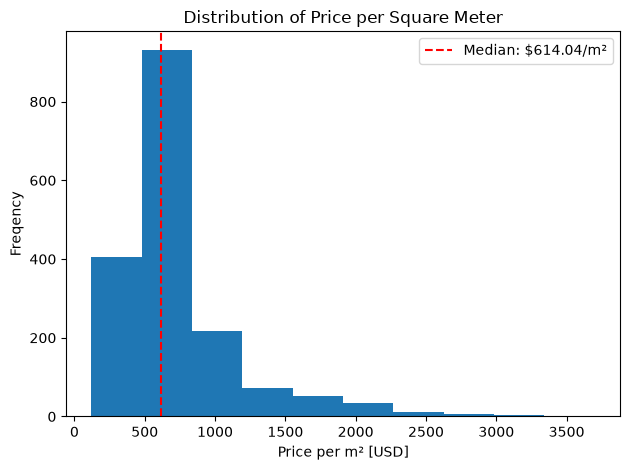

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

ax.hist(df["price_per_m2"])

ax.set_title("Distribution of Price per Square Meter")
ax.set_xlabel("Price per m² [USD]")
ax.set_ylabel("Freqency")

median_price_per_m2 = df["price_per_m2"].median()

ax.axvline(median_price_per_m2, color='red', linestyle='--',label=f'Median: ${median_price_per_m2:.2f}/m²')
ax.legend()

plt.tight_layout()
plt.show()


Reading the price_per_m2 distribution

Shape: Right-skewed. Most Mexican properties fall in a standard affordability range — roughly 200–800/m² — with a long tail of high-value properties extending to 2,000/m² and beyond.

The median (red dashed line): The median sits to the left of the distribution's visual center, confirming the right skew. Properties above the median are more spread out (long right tail) than properties below it.

Why right skew persists even after normalizing for size:

Dividing by area reduces some of the skewness (large cheap houses are removed from the right tail in terms of total price). But the location effect creates new right-tail values: a 60 m² apartment in Mexico City's Polanco neighborhood might cost 3,000/m² — an extreme value that still pulls the distribution right.

Mean vs median for this metric:

For the same reason as with total price, the median is the more honest "typical" value for price_per_m2. The mean is inflated by a small number of luxury urban properties. When we compare states in §4, we will use the median as our primary comparison metric.

The Location Effect: Grouped Analysis

The Group analysis workflow:

Aggregate
Rank
Visualize
Quantify

In [7]:
import pandas as pd

import pandas as pd

# data_path = "../data/mexico-real-estate-combined-clean.csv"

# data = pd.read_csv(data_path)

# df = data.assign(price_per_m2 = lambda x: x["price_usd"]/x["area_m2"] )

state_price_stats = (
    df
    .groupby("state")["price_per_m2"]
    .agg(["mean","median","std","count"])
    .sort_values(by="median", ascending=False)
    .round(2)
)

state_price_stats

,mean,median,std,count
state,,,,
Distrito Federal,1175.89,958.89,651.13,303
Guerrero,761.56,715.03,270.52,49
Quintana Roo,736.46,707.91,265.71,38
Oaxaca,683.02,683.02,196.87,2
Estado de México,763.75,674.30,396.69,179
Campeche,601.29,654.74,157.02,3
Nayarit,599.29,651.38,196.19,9
Querétaro,687.23,644.17,230.29,128
Jalisco,743.57,641.55,370.42,60


Visualizing Location Differences

We can make a boxplot of:
state -> price_per_m2

Now we can see much more than the mean.

We can compare:
- median
- IQR
- overall spread
- skew
- extreme observations
- statistical outliers

/tmp/ipykernel_107344/2055437348.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data_to_plot, tick_labels=target_states, vert=False)


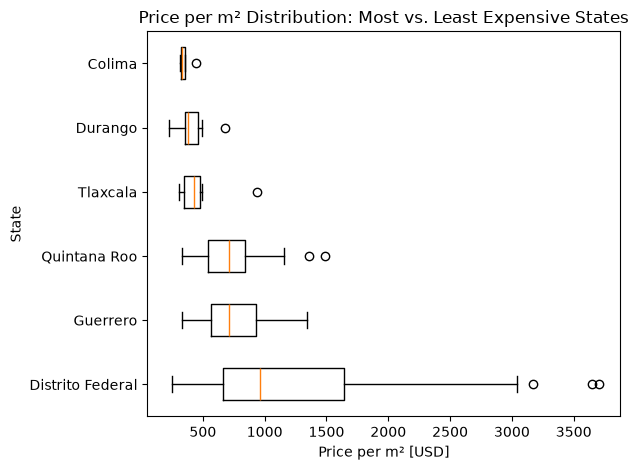

In [8]:
top_states = state_price_stats.head(3).index.tolist()
bottom_states = state_price_stats.tail(3).index.tolist()
target_states = top_states + bottom_states


df_states = df[df["state"].isin(target_states)]


data_to_plot = [df_states[df_states["state"] == state]["price_per_m2"]for state in target_states]


fig, ax = plt.subplots()

ax.boxplot(data_to_plot, tick_labels=target_states, vert=False)

ax.set_title("Price per m² Distribution: Most vs. Least Expensive States")
ax.set_xlabel("Price per m² [USD]")
ax.set_ylabel("State")

plt.tight_layout()
plt.show()

Between-group variation (the big story): The gap between the top states (Distrito Federal) and the bottom states is enormous. The median of Distrito Federal likely exceeds or approaches the maximum of the least expensive states. This is the Location Effect in its purest form: where a property sits geographically can matter more than any property-specific feature.

A numerical example: if the median price_per_m2 in Distrito Federal is 1000 and in colima is 300, then a 100 m² property in DF has a median value of 100000 while the same in colima is 30,000 — a 3× difference from location alone, before considering any other factor.

Quantifying Location vs Size Effects: Variance Decomposition

Properties in different states tend to live at different price levels.

But:
"Can we quantify how much of the overall price variation is associated with being in different states?"
That's the entire reason for this section.

In [9]:
# 1. Correlation between size and price
size_price_correlation = df[["area_m2", "price_usd"]].corr().iloc[0, 1]
print(f"Correlation between area and price: {size_price_correlation:.3f}")

# 2. Calculate variance components
# Total variance in price_usd
total_variance = df["price_usd"].var()

# Between-state variance (variance of state_means)
state_means = df.groupby("state")["price_usd"].mean()
between_variance = state_means.var()

# Within-state variance (average variance within each state)
within_variance = df.groupby("state")["price_usd"].var().mean()

# 3. Calculate percentages
between_pct = (between_variance / total_variance) * 100
within_pct = (within_variance / total_variance) * 100

print(f"\nVariance Decomposition:")
print(f"  Between-state variance: {between_pct:.1f}%")
print(f"  Within-state variance: {within_pct:.1f}%")
print(f"  Ratio (Between/Within): {between_variance/within_variance:.2f}")

Correlation between area and price: 0.586

Variance Decomposition:
  Between-state variance: 11.8%
  Within-state variance: 78.3%
  Ratio (Between/Within): 0.15


Reading the variance decomposition output

If between-state variance > within-state variance: This is the decisive evidence for the "location matters more" hypothesis. Knowing which state a property is in reduces our uncertainty about its price by more than knowing how large it is. The location effect is quantifiably larger than the size effect.

If within-state variance > between-state variance: The market is more uniform across states, and within-state variation (driven by size, property type, neighborhood) dominates.

The ratio (between/within): A ratio > 1.0 means between-state differences explain more than within-state differences — location dominates. A ratio < 1.0 means within-state differences dominate — other factors matter more.


Area and price have a moderate positive linear association (r = 0.586), indicating that larger properties tend to have higher prices. The grouped variance analysis shows relatively modest variation between state-level mean prices compared with the much larger variation among properties within states. This suggests that state alone does not account for most of the price variation in the dataset. However, this analysis does not establish that size is more important than location, because the correlation and variance components measure different quantities and within-state variation contains multiple factors such as size, city, neighborhood, and property type.



The Property Type Effect¶

We established that location drives price-per-m². But does property type also matter? Are apartments "denser" value stores than houses — even after normalizing for size?

/tmp/ipykernel_107344/2763896972.py:19: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data_by_type, tick_labels=prop_types, vert=False)


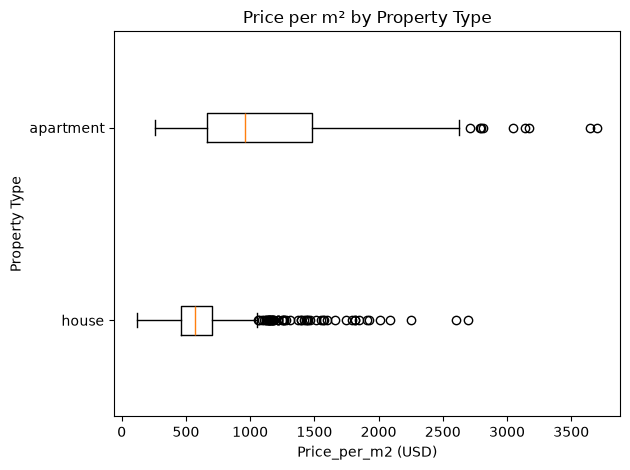

In [ ]:

property_type_stats = (
df.groupby("property_type")["price_per_m2"]
.agg(['mean', 'median', 'std','count'])
.sort_values(by="median", ascending=False)
.round(2)
)

property_type_stats

prop_types = df["property_type"].unique()


data_by_type = [df[df["property_type"]==p_type]["price_per_m2"]for p_type in prop_types]

fig, ax = plt.subplots()

ax.boxplot(data_by_type, tick_labels=prop_types, vert=False)
ax.set_title("Price per m² by Property Type")
ax.set_xlabel("Price_per_m2 (USD)")
ax.set_ylabel("Property Type")

plt.tight_layout()
plt.show()



Combined Analysis: State and Property Type

Location matters. Property type matters. But how do they interact? Is a Distrito Federal apartment dramatically more expensive per m² than a rural house? Or does the state effect dominate the property-type effect?

In [21]:
# 1. Group by both state and property_type
combined_stats = (
    df
    .groupby(["state", "property_type"])   # <-- "state" and "property_type"
    ["price_per_m2"]      
    .agg(['median', 'count'])
    .round(2)
)

# 2. Filter for groups with at least 5 properties
combined_stats_filtered = combined_stats[combined_stats['count'] >= 5]

# 3. Sort by median price per m²
combined_stats_filtered = combined_stats_filtered.sort_values(
    by='median', ascending=False
)

print("Top 15 State-Property Type Combinations:")
display(combined_stats_filtered.head(15))

print("\nBottom 10 State-Property Type Combinations:")
combined_stats_filtered.tail(10)

Top 15 State-Property Type Combinations:


,,median,count
state,property_type,,
Nuevo León,apartment,1424.90,12
Jalisco,apartment,1288.66,8
Distrito Federal,apartment,1140.09,214
Quintana Roo,apartment,1003.79,11
Querétaro,apartment,1003.41,12
Estado de México,apartment,969.18,27
Puebla,apartment,960.88,22
Veracruz de Ignacio de la Llave,apartment,818.62,10
Yucatán,apartment,799.68,21



Bottom 10 State-Property Type Combinations:


,,median,count
state,property_type,,
Hidalgo,house,526.86,17
San Luis Potosí,house,493.82,45
Sonora,house,486.06,12
Sinaloa,house,482.46,23
Yucatán,house,481.21,150
Veracruz de Ignacio de la Llave,house,474.18,107
Aguascalientes,house,436.44,10
Tlaxcala,house,424.56,6
Durango,house,372.30,6
